In [10]:
import pandas as pd
import numpy as np

In [37]:
data=pd.read_csv(r"C:\Users\VP\Downloads\bank.csv")

In [40]:
(data=='unknown').sum()   # Identifying the unknown values 
data[['job','education','contact','poutcome']]=data[['job','education','contact','poutcome']].replace('unknown',np.nan)# unknown converted into Nan values

In [ ]:
from sklearn.model_selection import train_test_split

x=data.drop(columns='deposit')  # Taking x without Y target
y=data['deposit']  #target
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=24)  # Splitting data 

number=x_train.describe(include='number').columns.tolist()  # Taking numerical columns separately 
catagory=x_train.describe(exclude='number').columns.tolist() # Taking Categorical column Sep

# print(x_train[catagory].isna().sum())
#x_train[x_train['poutcome']=='other']

# print(x_train['poutcome'].value_counts())
# x_train['poutcome'].isna().sum() 
# x_train[['poutcome','previous']].tail(20) # Noticed 0 is coming In previous Those values are coming unknown(nan)
 
 # Converting that nan Into not contacted Because previously not contacted as per data set
x_train['poutcome']=x_train['poutcome'].replace(np.nan,'not contacted') 
x_test['poutcome']=x_test['poutcome'].replace(np.nan,'not contacted')

x_train['contact']=x_train['contact'].fillna('no contact')  # Since the turn known values are majority contact I am separating One category
x_test['contact']=x_test['contact'].fillna('no contact')

In [112]:
x_train['education'].value_counts()

education
secondary    4381
tertiary     2984
primary      1178
Name: count, dtype: int64

In [133]:
x_train.groupby('default')['education'].value_counts()
x_train['education'] = x_train['education'].fillna('not_informed')
x_test['education'] = x_test['education'].fillna('not_informed')

In [ ]:
from sklearn.impute import SimpleImputer
si=SimpleImputer(strategy='most_frequent')

x_train['job']=si.fit_transform(x_train[['job']]).ravel()  # Here I am clatting due to get the series Hari so I am so storing in job
x_test['job']=si.transform(x_test[['job']]).ravel()

#x_test[['job']]=si.transform(x_test[['job']]) also works

In [ ]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False)
ohe.set_output(transform='pandas')
x_train_ohed=ohe.fit_transform(x_train[catagory])   # Converting the category column into a numerical column 
x_test_ohed=ohe.transform(x_test[catagory])



In [152]:
x_test_ohed

,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_not contacted,poutcome_other,poutcome_success
9936,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7920,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4664,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
221,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
10176,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3084,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6393,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5416,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1349,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Now handling the numerical columns

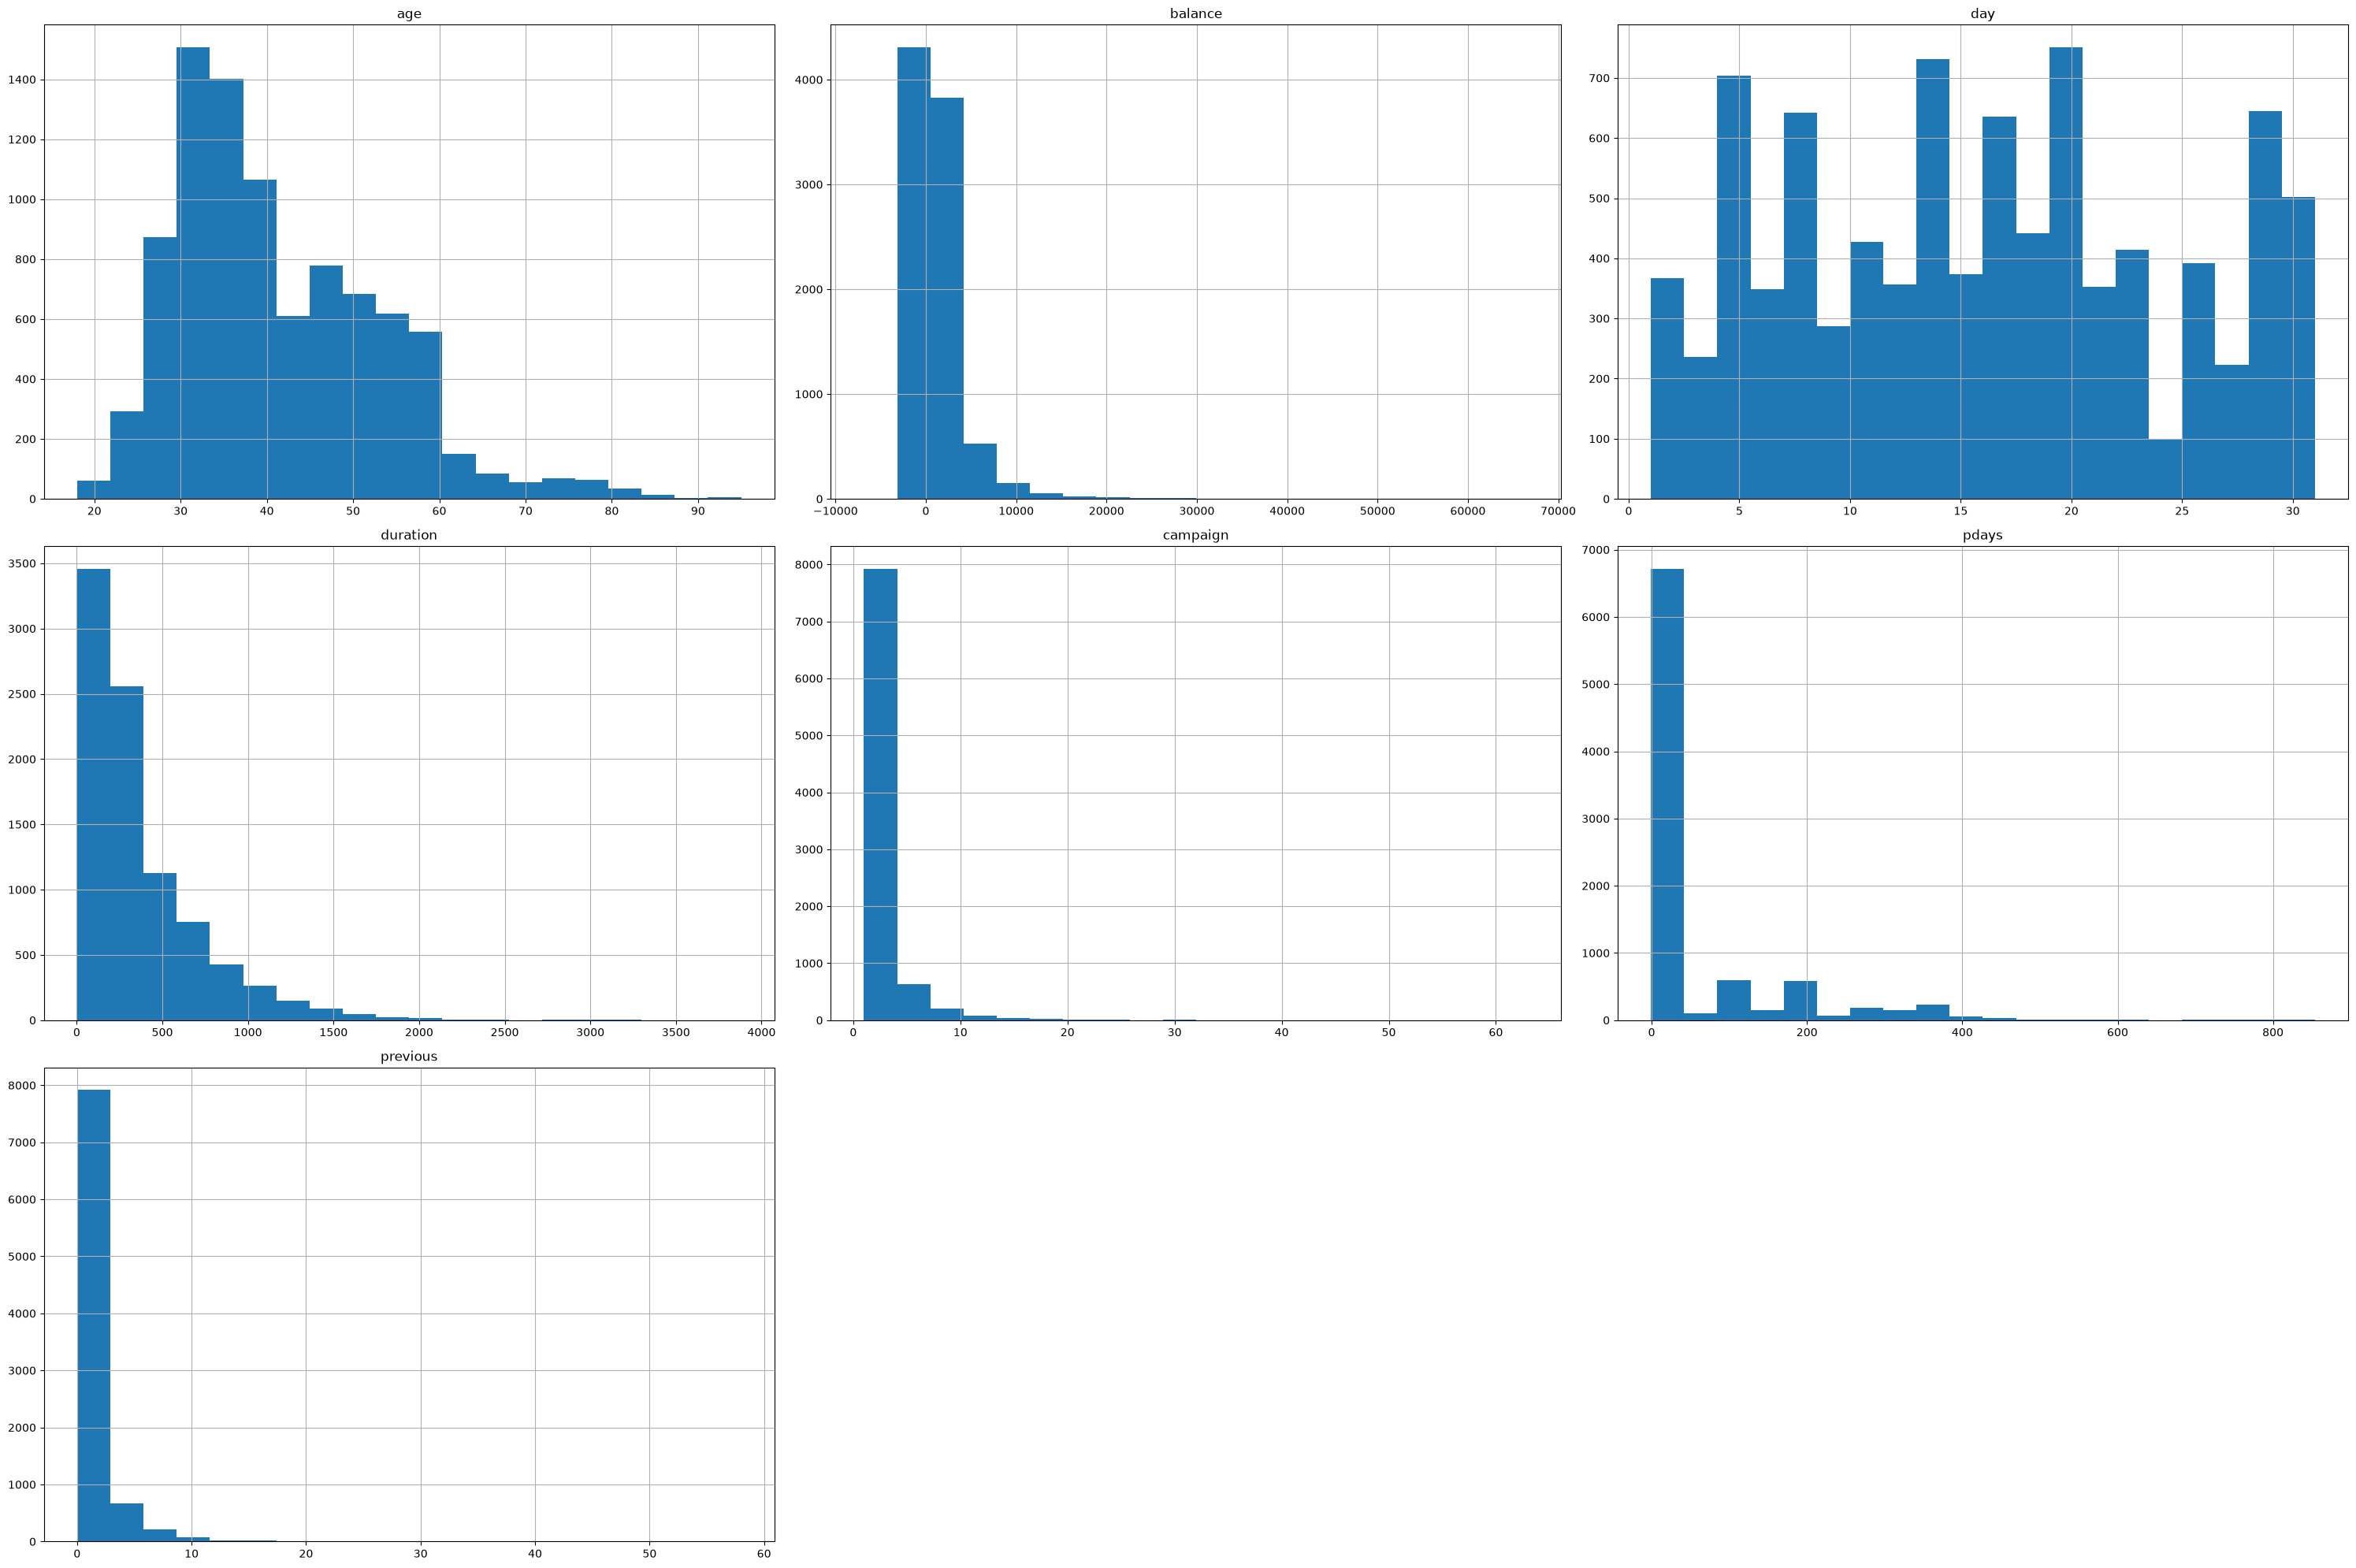

In [153]:
import matplotlib.pyplot as plt
x_train.hist(bins=20,figsize=(30,20))
plt.tight_layout()

In [ ]:
x_train[number].isna().sum()  # Verifying that There is no any missing values

x_train[number].skew(),x_train[number].min()

# x_train[log_columns]=np.log(x_train[log_columns])      Applying the log Transformation to the Column eligible

from sklearn.preprocessing import PowerTransformer
pt=PowerTransformer(method='yeo-johnson')
x_train['balance']=pt.fit_transform(x_train[['balance']])
x_test['balance']=pt.transform(x_test[['balance']])    # Doing transformation in ex test as well 

In [ ]:
from sklearn.preprocessing import PowerTransformer
pt=PowerTransformer(method='yeo-johnson')

x_train['pdays']=pt.fit_transform(x_train[['pdays']])  # Doing Ford rang summer for P days as well
x_test['pdays']=pt.transform(x_test[['pdays']])

In [189]:
from sklearn.preprocessing import RobustScaler
rs=RobustScaler()
x_train['previous']=rs.fit_transform(x_train[['previous']])
x_test['previous']=rs.transform(x_test[['previous']])

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'balance'}>,
        <Axes: title={'center': 'day'}>],
       [<Axes: title={'center': 'duration'}>,
        <Axes: title={'center': 'campaign'}>,
        <Axes: title={'center': 'pdays'}>],
       [<Axes: title={'center': 'previous'}>, <Axes: >, <Axes: >]],
      dtype=object)

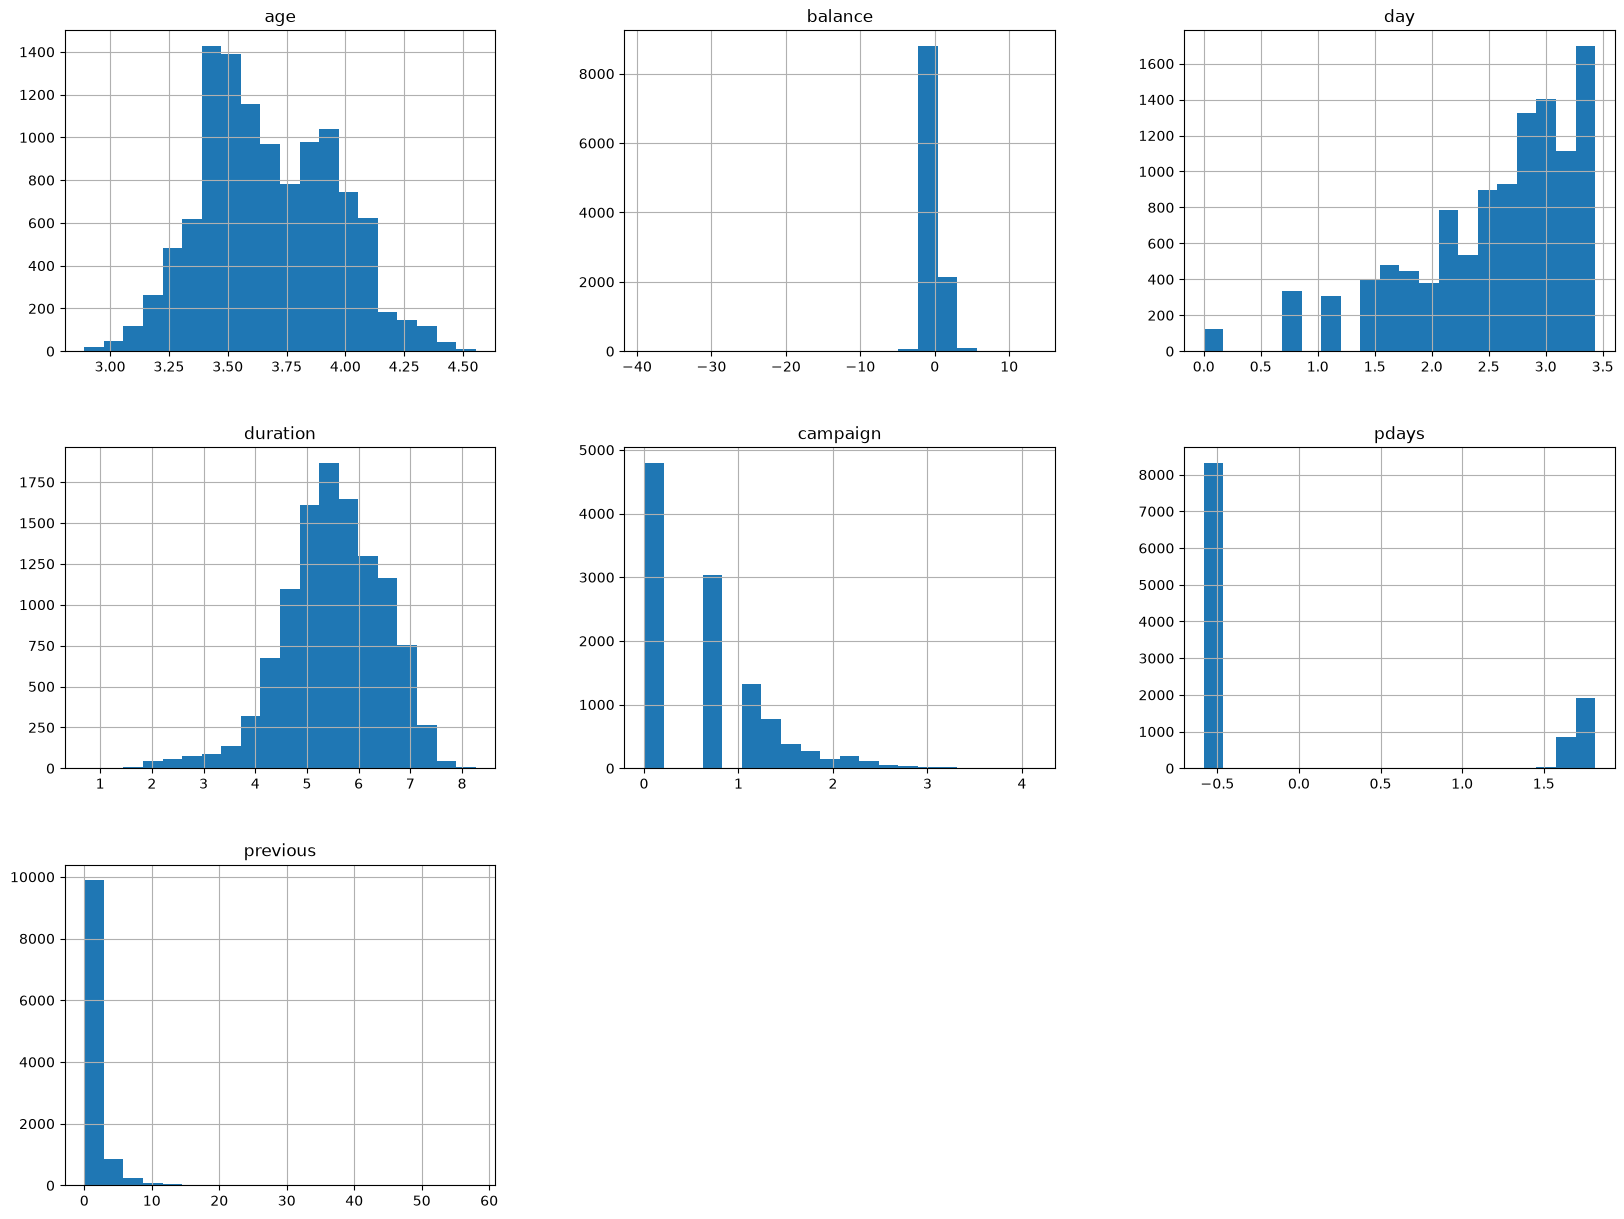

In [192]:
x_train.hist(bins=20,figsize=(20,15))

In [ ]:
x_test_final=pd.concat([x_test_ohed,x_test[number]],axis=1)

,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,...,poutcome_not contacted,poutcome_other,poutcome_success,age,balance,day,duration,campaign,pdays,previous
9936,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,45,243.976628,2,535,1,-0.583322,0.0
7920,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,51,1.920375,4,71,1,1.735616,3.0
4664,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,45,718.919774,28,365,4,-0.583322,0.0
221,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,25,104.192222,3,801,1,-0.583322,0.0
10176,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,27,561.473200,8,26,1,-0.583322,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3084,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,60,492.235348,15,295,3,1.770084,1.0
6393,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,27,38.152154,18,97,1,1.773830,1.0
5416,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,31,192.510644,12,51,1,-0.583322,0.0
1349,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,58,2355.691845,12,139,1,-0.583322,0.0


In [219]:
x_train_number=x_train.iloc[x_train_ohed.index.to_list()]

In [226]:
x_train_final=pd.concat([x_train_ohed,x_train_number],axis=1)

In [227]:
x_train_final

,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,...,poutcome_not contacted,poutcome_other,poutcome_success,age,balance,day,duration,campaign,pdays,previous
4334,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,3.218876,1.107772,3.178054,6.563856,0.000000,-0.583322,0.0
10381,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,3.583519,-0.466557,1.791759,6.139885,0.000000,-0.583322,0.0
810,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,3.988984,-0.206257,2.890372,6.253829,1.945910,-0.583322,0.0
10323,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,3.583519,-0.376590,2.484907,4.143135,1.609438,-0.583322,0.0
9203,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,4.060443,1.579161,3.044522,4.663439,1.098612,-0.583322,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5249,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,3.663562,-0.484962,2.890372,5.411646,1.098612,-0.583322,0.0
10385,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,4.025352,-0.250565,3.044522,2.564949,1.791759,-0.583322,0.0
3473,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,2.944439,-0.302765,3.401197,5.129899,0.000000,1.730041,2.0
8535,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,3.555348,-0.286261,3.044522,5.123964,0.693147,-0.583322,0.0
